## 1. Problem
Recover effective molecule number N, dark-state fraction T and diffusion residence time from Alexa488 confocal cross-correlation. This is conditional inference, not independent molecular truth. Absolute beam calibration is unavailable.

In [1]:
from pathlib import Path
import sys,time,json,numpy as np
root=Path.cwd()
if not (root/"src").exists(): root=root.parent
sys.path.insert(0,str(root))
from src.main import run
from src.preprocessing import load_observations
from src.solvers import reconstruct
from src.physics_model import correlation_model
from src.visualization import comparison_figure
import matplotlib.pyplot as plt

## 2. Data
All200 native float64 lag/correlation observations are loaded, without interpolation or synthetic replacement. Excess correlation is dimensionless; lag is in milliseconds. Independent background and beam-radius measurements are absent.

shape (200,) lag range ms [2.00000000e-04 2.68435456e+04] correlation range -0.00013305 0.15661088


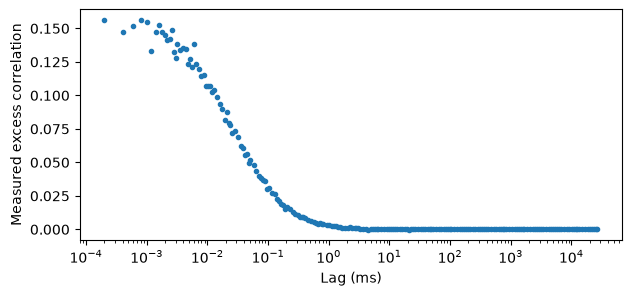

In [2]:
t,g=load_observations(root/"data/raw_data.npz")
print("shape",t.shape,"lag range ms",t[[0,-1]],"correlation range",g.min(),g.max())
fig,ax=plt.subplots(figsize=(7,3));ax.semilogx(t,g,".");ax.set(xlabel="Lag (ms)",ylabel="Measured excess correlation");plt.show()

## 3. Physics

The excess correlation predicted for a Gaussian confocal volume is

$$
G(t)=\frac{1+\frac{T}{1-T}\exp(-t/\tau_T)}{N(1+t/\tau_D)\sqrt{1+t/(S^2\tau_D)}}.
$$

Lag t and diffusion residence time tauD are in milliseconds; N is effective molecule number and T is the dimensionless dark-state fraction. The fixed dark-state time is tauT=0.002 ms, the axial/lateral aspect ratio is S=5, and the additive offset is zero. These are conditional model assumptions from the author session, rather than independently measured sample truth. No unknown beam-radius calibration is manufactured.


## 4. Method
Minimize the unweighted sum of squared residuals over every lag with 0<N<=100000, 0<=T<=0.95 and 0.002<=d<=1000 ms. A bounded trust-region nonlinear least-squares fit implements the declared continuous conditional target. A fresh no-triplet fit provides a physical model comparison. The independent upstream result is identified separately.

In [3]:
start=time.perf_counter()
p,m,sse=run(root)
q,m0,sse0=reconstruct(t,g,triplet=False)
runtime=time.perf_counter()-start
up=np.load(root/"notebooks/reference_outputs/upstream_repeat.npz",allow_pickle=False)
print("Fresh local parameters [N,T,d_ms]:",p)
print("Independent upstream repeat parameters:",up["output_parameters"][[0,1,3]])
print("Fresh local no-triplet:",q)
print("SSE full / no-triplet:",sse,sse0,"runtime seconds",runtime)
from IPython.display import display, Markdown
up_p=up["output_parameters"][[0,1,3]]
rows=["| Quantity | Unit | Upstream repeat | Fresh local | Relative difference |", "|---|---|---:|---:|---:|"]
for label,unit,index in [("Effective population N","1",0),("Dark-state fraction T","1",1),("Residence time tauD","ms",2)]:
    rows.append(f"| {label} | {unit} | {up_p[index]:.9g} | {p[index]:.9g} | {abs(p[index]/up_p[index]-1):.3g} |")
display(Markdown("\n".join(rows)))


Fresh local parameters [N,T,d_ms]: [6.5589467  0.02669958 0.02673119]
Independent upstream repeat parameters: [6.55894707 0.02669966 0.0267312 ]
Fresh local no-triplet: [6.477323   0.         0.02597975]
SSE full / no-triplet: 0.0010576869285375528 0.0010766790636566998 runtime seconds 0.0051905999425798655


| Quantity | Unit | Upstream repeat | Fresh local | Relative difference |
|---|---|---:|---:|---:|
| Effective population N | 1 | 6.55894707 | 6.5589467 | 5.66e-08 |
| Dark-state fraction T | 1 | 0.0266996612 | 0.0266995785 | 3.1e-06 |
| Residence time tauD | ms | 0.0267311994 | 0.0267311945 | 1.83e-07 |

## 5. Results
Compare the active local reconstruction, independent upstream run, measured data and freshly fitted no-triplet model. Residual and one-parameter sensitivity views expose model coupling. No cached method is labeled as fresh.

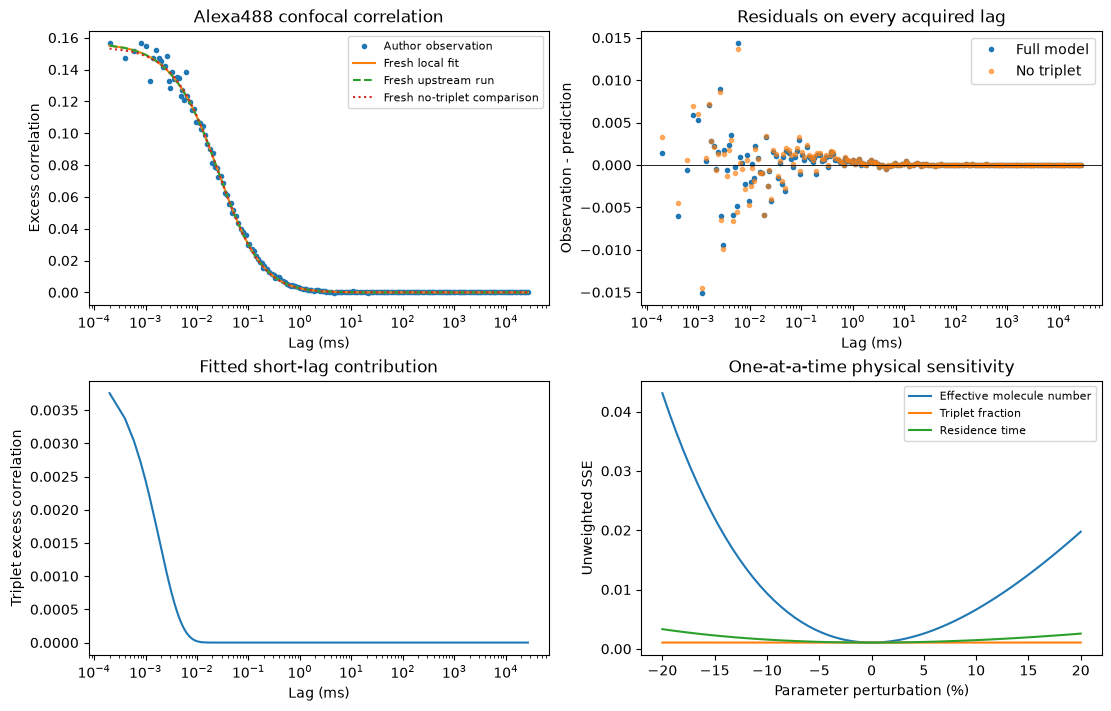

{
  "status": "pass",
  "passed": true,
  "metrics": {
    "parameter_relative_max": 3.314144364112182e-06,
    "curve_relative_l2": 2.5805323234297978e-08,
    "model_consistency_relative_l2": 1.2204410554877253e-16,
    "observation_sse": 0.0010576869285375528
  },
  "thresholds": {
    "parameter_relative_max": {
      "comparison": "<=",
      "boundary": 0.0001
    },
    "curve_relative_l2": {
      "comparison": "<=",
      "boundary": 1e-06
    },
    "model_consistency_relative_l2": {
      "comparison": "<=",
      "boundary": 1e-10
    },
    "observation_sse": {
      "comparison": "<=",
      "boundary": 0.003
    }
  },
  "errors": []
}


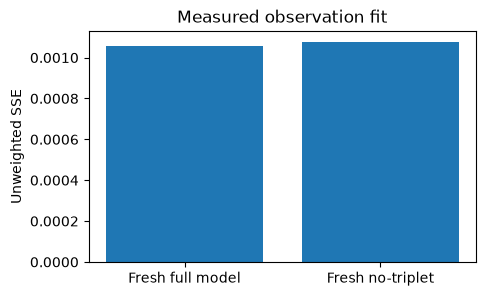

In [4]:
fig=comparison_figure(t,g,p,m,up["output_curve"],m0)
plt.show()
import importlib.util
spec=importlib.util.spec_from_file_location("judge",root/"evaluation/judge.py");j=importlib.util.module_from_spec(spec);spec.loader.exec_module(j)
report,exitcode=j.evaluate(root/"output/reconstruction.npz")
print(json.dumps(report,indent=2));assert exitcode==0
fig,ax=plt.subplots(figsize=(5,3));ax.bar(["Fresh full model","Fresh no-triplet"],[sse,sse0]);ax.set(ylabel="Unweighted SSE",title="Measured observation fit");plt.show()

## 6. Conclusion
The three-parameter conditional model recovers the independently reproduced standard analysis and explains the measured correlation decay. Short-lag triplet effects are weak and parameter coupling remains. The reference is a method result, not physical ground truth; this dataset supports effective populations and residence time without absolute concentration or diffusion claims.